# #61 — Single-Cell-Resolution Spatial Transcriptomics (10x Xenium)

Real 10x Xenium dataset: **`Xenium_FFPE_Human_Breast_Cancer_Rep1`** -- the companion dataset to Janesick
et al. 2023, *Nature Communications* 14:8353. 167,782 real segmented cells from real FFPE human breast
tumor tissue, each with a real 313-gene targeted-panel expression profile AND a real (x, y) spatial
position -- true single-cell resolution, unlike project #5's Visium spots (1-10 cells/spot).

**The real question:** which real cell TYPES sit next to which other real cell types in real tissue, more
or less than chance predicts -- a question spot-based spatial transcriptomics structurally cannot answer.

Read `PROJECT_NARRATIVE.md` and `WORKFLOW.md` before starting. Docs to look up as you go: scanpy
(`https://scanpy.readthedocs.io`), squidpy (`https://squidpy.readthedocs.io`).


## Step 0 — Fetch the real data and set up

**Real file, real source, downloaded ONCE on your own machine** (this teaching environment's sandbox has
restricted outbound network access to most bioinformatics hosts -- confirmed directly during this
project's build). Run this on your own machine / Kaggle / Colab:

```bash
mkdir -p data
curl -L -o data/Xenium_outs.zip \
  https://cf.10xgenomics.com/samples/xenium/1.0.1/Xenium_FFPE_Human_Breast_Cancer_Rep1/Xenium_FFPE_Human_Breast_Cancer_Rep1_outs.zip
unzip -o data/Xenium_outs.zip -d data/xenium_outs
ls data/xenium_outs
```

You should see `cell_feature_matrix.h5` (real per-cell x per-gene counts) and `cells.csv.gz` (real per-cell
spatial centroid + QC columns: `cell_id`, `x_centroid`, `y_centroid`, `transcript_counts`, `cell_area`,
`nucleus_area`, ...) among the real output files -- these are the two this project needs.

**Note:** `squidpy.read.xenium()` does NOT exist in the squidpy version confirmed in this project's build
(1.6.5) -- loading is done manually below instead, which also works regardless of squidpy version.


In [1]:
pip install scanpy squidpy leidenalg igraph --quiet

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Note: you may need to restart the kernel to use updated packages.


In [3]:
!mkdir -p data
!curl -L -o data/Xenium_outs.zip https://cf.10xgenomics.com/samples/xenium/1.0.1/Xenium_FFPE_Human_Breast_Cancer_Rep1/Xenium_FFPE_Human_Breast_Cancer_Rep1_outs.zip
!unzip -o data/Xenium_outs.zip -d data/xenium_outs
!ls data/xenium_outs

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 9404M  100 9404M    0     0   154M      0  0:01:00  0:01:00 --:--:--  274M
Archive:  data/Xenium_outs.zip
   creating: data/xenium_outs/outs/
  inflating: data/xenium_outs/outs/experiment.xenium  
   creating: data/xenium_outs/outs/cell_feature_matrix/
  inflating: data/xenium_outs/outs/cell_feature_matrix/barcodes.tsv.gz  
  inflating: data/xenium_outs/outs/cell_feature_matrix/features.tsv.gz  
  inflating: data/xenium_outs/outs/cell_feature_matrix/matrix.mtx.gz  
  inflating: data/xenium_outs/outs/cell_feature_matrix.h5  
 extracting: data/xenium_outs/outs/cell_feature_matrix.zarr.zip  
 extracting: data/xenium_outs/outs/analysis.zarr.zip  
   creating: data/xenium_outs/outs/analysis/
   creating: data/xenium_outs/outs/analysis/clustering/
   creating: data/xenium_outs/outs/analysis/clustering/gene_expression_graphclust/
  i

In [5]:
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq
import matplotlib.pyplot as plt

sc.settings.verbosity = 1

# GIVEN: load the real per-cell x per-gene matrix (same function #40 used for its 10x .h5 file)
adata = sc.read_10x_h5("data/xenium_outs/outs/cell_feature_matrix.h5")
adata.var_names_make_unique()
print(adata)


AnnData object with n_obs × n_vars = 167780 × 313
    var: 'gene_ids', 'feature_types', 'genome'
    layers: None (.X)


## Step 1 — Attach the real spatial coordinates

**WHAT·WHY·HOW:** `cells.csv.gz` has one real row per cell, in the real `cell_id`, `x_centroid`,
`y_centroid`, ... format confirmed from 10x's own Xenium output documentation. Load it, align it to
`adata.obs_names` (the matrix's real cell-barcode order), and store the real (x, y) centroid as a 2-column
array in `adata.obsm['spatial']` -- the standard real place scanpy/squidpy functions look for spatial
coordinates.


In [10]:
cells_df = pd.read_csv("data/xenium_outs/outs/cells.csv.gz")
cells_df = cells_df.set_index("cell_id")

print(cells_df.index[:5].tolist())
print(adata.obs_names[:5].tolist())

cells_df.index = cells_df.index.astype(str)

cells_df = cells_df.loc[adata.obs_names]
adata.obsm["spatial"] = cells_df[["x_centroid", "y_centroid"]].values
adata.obs["transcript_counts"] = cells_df["transcript_counts"].values

print("spatial shape:", adata.obsm["spatial"].shape)

[1, 2, 3, 4, 5]
['1', '2', '3', '4', '5']
spatial shape: (167780, 2)


## Step 2 — QC on real terms

**WHAT·WHY·HOW:** Targeted Xenium panels have far fewer genes than whole-transcriptome RNA-seq (313
real genes here vs ~20-30k for #4/#40), so real per-cell total counts are naturally much lower -- don't
reuse #4/#40's RNA-seq QC thresholds unmodified. Plot the real distributions first, same house rule as
every other project: never hardcode a threshold you haven't looked at.


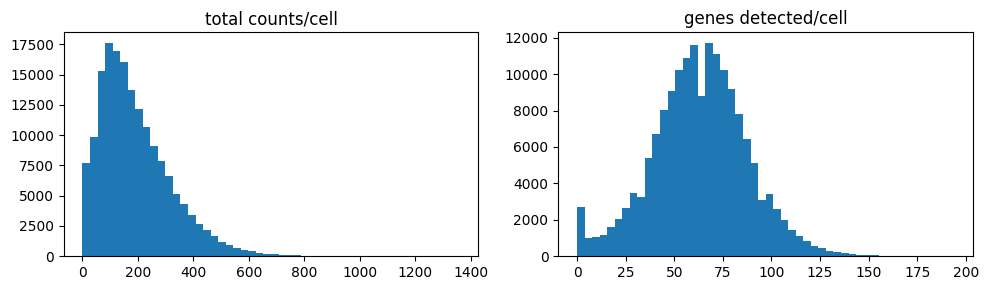

In [11]:
sc.pp.calculate_qc_metrics(adata, inplace=True, percent_top=None)

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(adata.obs["total_counts"], bins=50); axes[0].set_title("total counts/cell")
axes[1].hist(adata.obs["n_genes_by_counts"], bins=50); axes[1].set_title("genes detected/cell")
plt.tight_layout()
import os; os.makedirs("results", exist_ok=True)
plt.savefig("results/qc_distributions.png", dpi=120)
plt.show()


In [12]:
# WRITE-IT: set real thresholds from what you just saw -- a real targeted panel's low end often needs
# a much lower min-counts cutoff than whole-transcriptome RNA-seq (e.g. tens, not hundreds)
min_counts = 10   # look at your histogram

keep = adata.obs["total_counts"] >= min_counts
print(f"keeping {keep.sum()} / {len(keep)} real cells")
adata = adata[keep].copy()


keeping 164000 / 167780 real cells


## Step 3 — Baseline clustering

**WHAT·WHY·HOW:** Same real method family as #4/#40 -- normalize, log-transform, PCA, neighbors, Leiden,
UMAP. This clustering is spatially blind (built from expression alone) on purpose, so the real spatial
test later (Step 5) is an independent check, not something baked into the clustering objective.


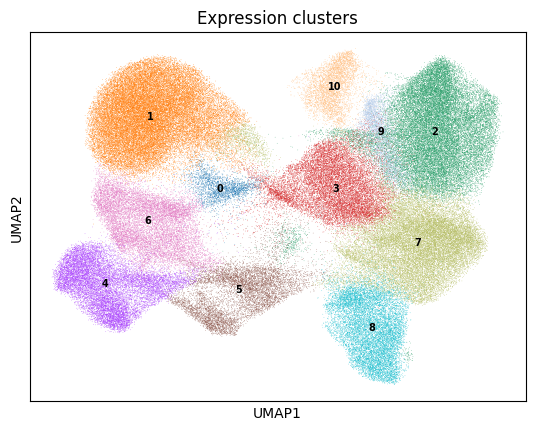

In [13]:
adata.layers["counts"] = adata.X.copy()

sc.pp.normalize_total(adata)
sc.pp.log1p(adata)
sc.pp.pca(adata, n_comps=20)
sc.pp.neighbors(adata)
sc.tl.leiden(adata, flavor="igraph", n_iterations=2, resolution=0.5)
sc.tl.umap(adata)

sc.pl.umap(adata, color="leiden", legend_loc="on data", legend_fontsize=7, title="Expression clusters")


## Step 4 — Real marker-based cell typing

**WHAT·WHY·HOW (biology):** A targeted panel doesn't cover the whole transcriptome, so full-atlas
reference-mapping tools expect genes this panel doesn't have -- curated real marker-gene-set scoring is
the real, panel-appropriate method instead. Score each real cell against each real canonical marker set,
assign the highest-scoring real type per cell.

**Real, caught issue (don't skip):** `sc.tl.score_genes` can fail outright on small gene panels with its
default settings -- it bins genes by expression level to pick matched control genes, and with only ~300
real genes total, some bins come up empty. Confirmed directly during this project's build; the real fix is
`ctrl_as_ref=False, n_bins=10` (or similar), not a default call.


In [14]:
marker_sets = {
    "Tumor_epithelial": ["EPCAM", "KRT8", "ERBB2"],
    "Immune": ["PTPRC", "CD3D", "CD68"],
    "Stromal": ["ACTA2", "PDGFRB"],
    "Endothelial": ["PECAM1", "VWF"],
}
# keep only real genes that actually exist in this real 313-gene panel
marker_sets = {ct: [g for g in genes if g in adata.var_names] for ct, genes in marker_sets.items()}
for ct, genes in marker_sets.items():
    print(ct, "->", genes)

for ct, genes in marker_sets.items():
    sc.tl.score_genes(adata, gene_list=genes, score_name=f"score_{ct}", ctrl_as_ref=False, n_bins=10)
    # adata, genes

score_cols = [f"score_{ct}" for ct in marker_sets]
adata.obs["cell_type"] = adata.obs[score_cols].idxmax(axis=1).str.replace("score_", "", regex=False)
adata.obs["cell_type"] = adata.obs["cell_type"].astype("category")   # required by squidpy's nhood_enrichment

adata.obs["cell_type"].value_counts()


Tumor_epithelial -> ['EPCAM', 'KRT8', 'ERBB2']
Immune -> ['PTPRC', 'CD3D', 'CD68']
Stromal -> ['ACTA2', 'PDGFRB']
Endothelial -> ['PECAM1', 'VWF']


cell_type
Tumor_epithelial    82531
Immune              35057
Stromal             29585
Endothelial         16827
Name: count, dtype: int64

## Step 5 — Real cell-type spatial neighborhood enrichment

**WHAT·WHY·HOW (math -> biology):** Build a real spatial k-nearest-neighbors graph from real cell
centroids, then run a real permutation test comparing the real observed count of each cell-type-pair's
physical adjacencies against the same count under many random real relabelings of cell type onto the same
real spatial graph -- a z-score per type-pair. Positive = real spatial co-localization (more neighboring
pairs than chance); negative = real spatial avoidance.


In [15]:
sq.gr.spatial_neighbors(adata, coord_type="generic", n_neighs=6)
sq.gr.nhood_enrichment(adata, cluster_key="cell_type", seed=0)

zscore = adata.uns["cell_type_nhood_enrichment"]["zscore"]
categories = adata.obs["cell_type"].cat.categories.tolist()
zscore_df = pd.DataFrame(zscore, index=categories, columns=categories)
zscore_df.to_csv("results/nhood_enrichment_zscores.csv")
zscore_df.round(2)


INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_48/10202633.py:1: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata, coord_type="generic", n_neighs=6)   # adata


  0%|          | 0/1000 [00:00<?, ?/s]

,Endothelial,Immune,Stromal,Tumor_epithelial
Endothelial,153.52,47.53,73.12,-215.27
Immune,45.16,289.77,27.45,-337.39
Stromal,78.33,32.77,181.18,-239.17
Tumor_epithelial,-189.23,-303.86,-220.66,448.57


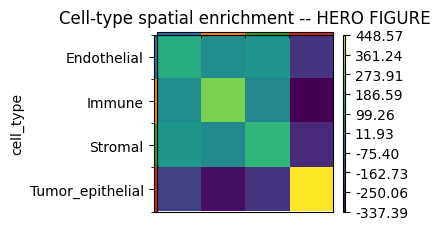

In [16]:
sq.pl.nhood_enrichment(adata, cluster_key="cell_type", title="Cell-type spatial enrichment -- HERO FIGURE")
plt.savefig("results/hero_nhood_enrichment.png", dpi=150, bbox_inches="tight")
plt.show()


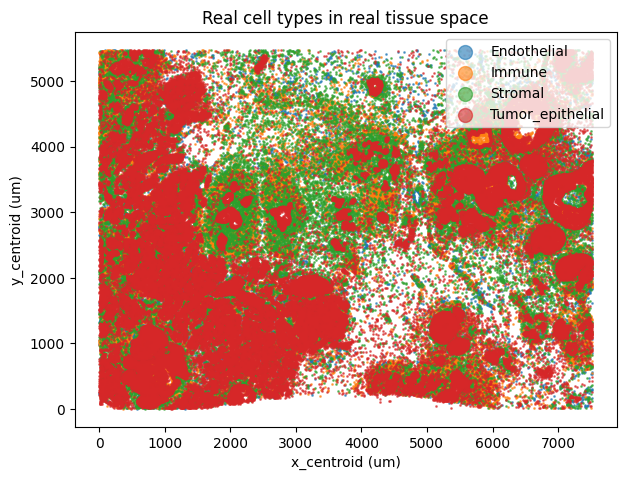

In [17]:
fig, ax = plt.subplots(figsize=(7, 7))
coords = adata.obsm["spatial"]
for ct in adata.obs["cell_type"].cat.categories:
    mask = adata.obs["cell_type"] == ct
    ax.scatter(coords[mask, 0], coords[mask, 1], s=1, label=ct, alpha=0.6)
ax.legend(markerscale=10, loc="upper right")
ax.set_title("Real cell types in real tissue space")
ax.set_xlabel("x_centroid (um)"); ax.set_ylabel("y_centroid (um)")
ax.set_aspect("equal")
plt.savefig("results/spatial_celltype_map.png", dpi=150, bbox_inches="tight")
plt.show()


## Step 6 — Export real results


In [18]:
import os
os.makedirs("results", exist_ok=True)

adata.obs[["cell_type", "leiden", "total_counts"]].to_csv("results/cell_type_annotations.csv")

print("Done. Real results written to results/.")


Done. Real results written to results/.
